In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from OBM_functions import *

plt.rcParams['font.size'] = 12
plt.rcParams['font.family'] = ['Times New Roman', 'DejaVu Serif']

# OBM Hands-on Tutorial
### Spotting a non-transiting companion in a *Kepler* light curve

In this session you will:

1. load *Kepler* long-cadence light curves and stellar properties,
2. compute the power spectral density (PSD) of a light curve,
3. tell a **stellar-activity peak** (rotation, harmonics) apart from a **candidate orbital signal**,
4. measure the period of that signal and check its **stability** by phase folding.

**Prerequisites**

| File | Role |
|---|---|
| `OBM_functions.py` | helper functions used throughout (`retrieve_KIC_info`, `compute_PSD`, `plot_PSD`, etc) |
| `LightCurves/*.fits` | the stellar light curves (KIC 9837312, KIC 7847566, KIC 11154093 and KIC 3351888) |
| `Santos_stellar_data.csv` | stellar properties, Santos et al. (2019, 2021) |


## 1. Data

We study four stars, listed in `KIC_num`. Stellar properties come from Santos et al. (2019, 2021). 

**Data used**
- Long-cadence *Kepler* data
- High-pass filter at 20 days
- Calibrated with the KEPSEISMIC method (García et al., 2011, 2014; Pires et al., 2015)

In [2]:
#---------------------------------
# Path parameters & general infos
#---------------------------------
pathfile  = 'LightCurves/' #where the light curves are
figfolder = 'figures/' #where to save the figures
os.makedirs(figfolder, exist_ok=True)
files     = "*.fits" # light curves
stellar_info = 'Santos_stellar_data.csv'#Stellar informations, Santos et al. 2019, 2021

KIC_num = [9837312, 7847566, 3351888, 11154093]

In [3]:
#---------------------
# Unpack data
#---------------------
df_stellar = pd.read_csv(stellar_info, index_col='KIC')
df = df_stellar.loc[KIC_num].copy()
KICfiles = glob.glob(os.path.join(pathfile, files))
df['filenames'] = [find_lightcurves(kic, KICfiles) for kic in df.index]
df

,Prot,Teff,Mass,Kpmag,logg,filenames
KIC,,,,,,
9837312,4.99,5910.5,1.327,12.953,3.757,LightCurves/kplr009837312_3667_COR_filt_inp.fits
7847566,28.58,3401.0,0.321,15.095,4.921,LightCurves/kplr007847566_2327_COR_filt_inp.fits
3351888,33.99,5666.7,1.029,15.001,4.473,LightCurves/kplr003351888_COR_filt_inp.fits
11154093,10.39,5888.3,1.042,15.423,4.292,LightCurves/kplr011154093_COR_filt_inp.fits


## 2. Method: look for a high-amplitude peak in the PSD

We compute the PSD of each light curve to look for a **high-amplitude peak** that could be linked to a **non-transiting object**.

### 2.1. First case: KIC 9837312

In [4]:
kic1 = 9837312 #first case example
t1, v1, Prot1 = retrieve_KIC_info(df, kic1)
psd1, freq1 = compute_PSD(t1, v1) #take a few seconds...
print(f'Currently studying KIC {kic1}')

Currently studying KIC 9837312


/Users/cg269601/Desktop/Conferences/LorentzCenter26/OBM_functions.py:96: RuntimeWarning: divide by zero encountered in divide
  return 1/(86400*(freq*1e-6))


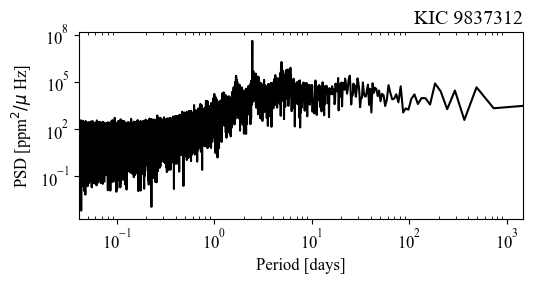

In [5]:
fig1, ax1 = plot_PSD(kic1, freq1, psd1, Prot1)
fig1.savefig(f'figures/{kic1}_psd.png', dpi=300)

A sharp, high-amplitude peak stands out at a period of about 2.5 days. A first suspect is stellar activity, so let's compare it with the rotation period $P_{\rm rot}$.

/Users/cg269601/Desktop/Conferences/LorentzCenter26/OBM_functions.py:96: RuntimeWarning: divide by zero encountered in divide
  return 1/(86400*(freq*1e-6))


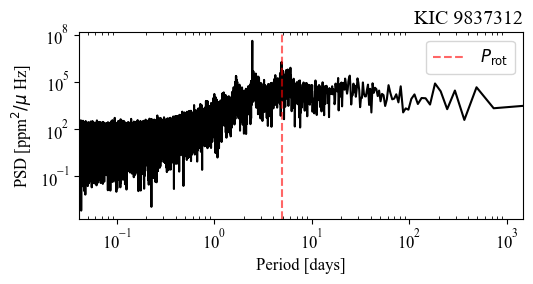

In [6]:
fig1, ax1 = plot_PSD(kic1, freq1, psd1, Prot1)
ax1.axvline(Prot1,color='red', linestyle='--', alpha=0.6, label=r'$P_{\rm rot}$')
plt.legend()
fig1.savefig(f'figures/{kic1}_psd_withProt.png', dpi=300)
plt.show()

The peak does **not** coincide with $P_{\rm rot}$ (4.99 days). However, rotational modulation is rarely a pure sinusoid, so it also puts power at the harmonics of $P_{\rm rot}$ ($P_{\rm rot}/2$, $P_{\rm rot}/3$, ...). Let's add the first harmonic.

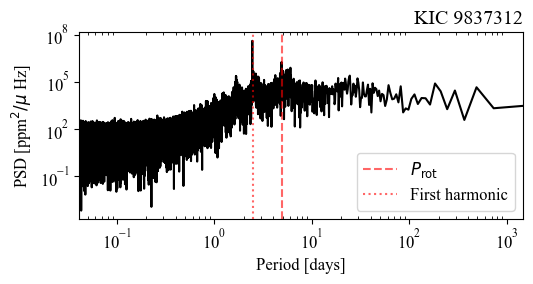

The stellar rotation period value is 4.99 days
The first harmomic of the stellar rotation period value is 2.495 days


In [7]:
fig1, ax1 = plot_PSD(kic1, freq1, psd1, Prot1)
ax1.axvline(Prot1, color='red', linestyle='--', alpha=0.6, label=r'$P_{\rm rot}$')
ax1.axvline(Prot1/2, color='red', linestyle=':', alpha=0.6, label=r'First harmonic')
plt.legend()
fig1.savefig(f'figures/{kic1}_psd_withHarmonic.png', dpi=300)
plt.show()

print(f'The stellar rotation period value is {Prot1} days')
print(f'The first harmomic of the stellar rotation period value is {Prot1/2} days') 


**Take-away:** the peak sits at $P_{\rm rot}/2 = 2.495$ days. It is the first harmonic of the rotation signal, hence a stellar-activity signature and not a companion.

### 2.2. Second case: KIC 7847566

In [8]:
kic2 = 7847566 #second case example
t2, v2, Prot2 = retrieve_KIC_info(df, kic2)
psd2, freq2 = compute_PSD(t2, v2) #take a few seconds...
print(f'Currently studying KIC {kic2}')

Currently studying KIC 7847566


/Users/cg269601/Desktop/Conferences/LorentzCenter26/OBM_functions.py:96: RuntimeWarning: divide by zero encountered in divide
  return 1/(86400*(freq*1e-6))


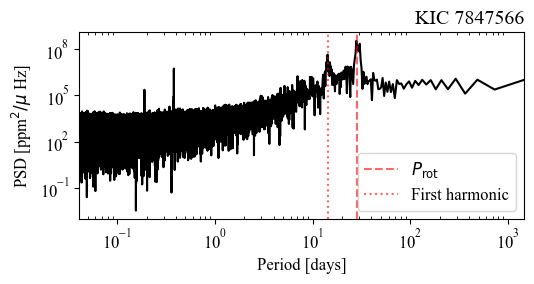

In [9]:
fig2, ax2 = plot_PSD(kic2, freq2, psd2, Prot2)
ax2.axvline(Prot2, color='red', linestyle='--', alpha=0.6, label=r'$P_{\rm rot}$')
ax2.axvline(Prot2/2, color='red', linestyle=':', alpha=0.6, label=r'First harmonic')
plt.legend()
fig2.savefig(f'figures/{kic2}_psd_withHarmonic.png', dpi=300)
plt.show()

The highest peaks are the rotation period and its harmonic. But look closely at the short-period side: there is two **narrow, isolated spike**.

> is that spike related to the a non-transiting companion?

### 2.3. Find the period of the signal

Rather than reading the period off the plot, we search for it automatically with `find_companion_peak`. The function:

1. keeps only the PSD values above a detection threshold, so that only significant peaks remain,
2. ignores the stellar-activity peaks ($P_{\rm rot}$ and its harmonics): they are orders of magnitude higher than the spike we are after and would otherwise always win,
3. returns the frequency (in µHz) and the PSD value of the highest remaining peak.

In [10]:
freq_max2, psd_max2 = find_compagnon_peak(freq2, psd2, Prot2)

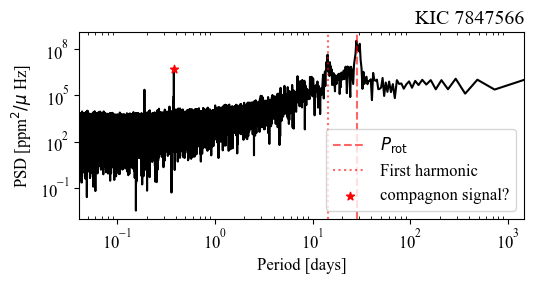

In [11]:
fig2, ax2 = plot_PSD(kic2, freq2, psd2, Prot2)
ax2.axvline(Prot2,color='red', linestyle='--', alpha=0.6, label=r'$P_{\rm rot}$')
ax2.axvline(Prot2/2,color='red', linestyle=':', alpha=0.6, label=r'First harmonic')
ax2.scatter(convert_freq_to_Porb(freq_max2),psd_max2 , color = 'red', marker = "*", label='compagnon signal?', zorder=100) 
plt.legend()
fig2.savefig(f'figures/{kic2}_psd_compagnon.png', dpi=300)
plt.show()

The red star marks the detected peak. If it is caused by a companion, its period is the **orbital period** of the object. For now it is only a **candidate**: the next section tests whether the signal is real.

In [12]:
Porb = convert_freq_to_Porb(freq_max2)
print(f"Around KIC {kic2}, the detected object's orbital period is {np.round(Porb,2)} days.")

Around KIC 7847566, the detected object's orbital period is 0.38 days.


## 3. Is the signal stable? Phase folding

A companion should produce a modulation that is periodic and **coherent** over the whole *Kepler* observation (around 4 years). We therefore fold the light curve at the candidate period $P_{\rm orb}$: all cycles are stacked on top of each other and the flux is plotted against the orbital phase. Black points are individual measurements and red points a smoothed version.

- a **stable** signal gives a clean, repeatable modulation,
- a signal that **drifts or changes amplitude** points to a false positive (e.g. contamination by a neighbouring star).

### 3.1. KIC 7847566: a stable signal

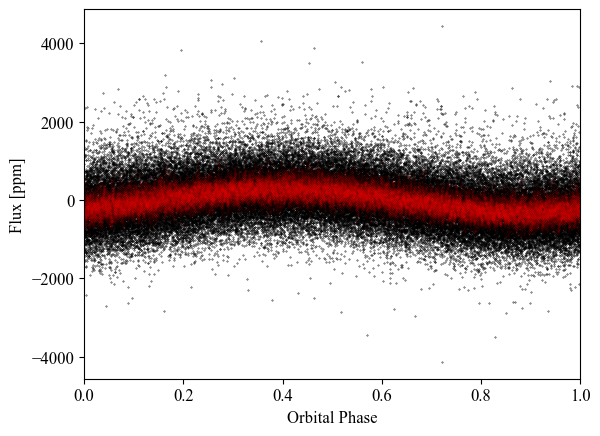

In [13]:
# Phase folding #
fig3, ax3 = plot_phase_fold(t2, v2, Porb) #takes a few seconds...
fig3.savefig(f'figures/{kic2}_phase_folding.png', dpi=300)
plt.show()

Folded at 0.38 day, the light curve shows a smooth, quasi-sinusoidal modulation. It is the same over the entire dataset: the signal is **coherent**.

### 3.2. KIC 11154093: a counter-example

To see what an *unstable* signal looks like, we apply exactly the same procedure to KIC 11154093.

In [14]:
kic3 = 11154093 #third case example
t3, v3, Prot3 = retrieve_KIC_info(df, kic3)
psd3, freq3 = compute_PSD(t3, v3) #take a few seconds...
print(f'Currently studying KIC {kic3}')

Currently studying KIC 11154093


KIC 11154093: P = 0.26 days


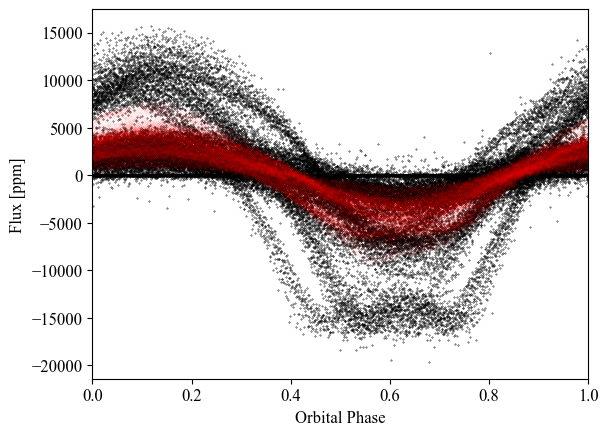

In [15]:
freq_max3, psd_max3 = find_compagnon_peak(freq3, psd3, Prot3)
Porb3 = convert_freq_to_Porb(freq_max3)
print(f'KIC {kic3}: P = {Porb3:.2f} days')
fig3, ax3 = plot_phase_fold(t3, v3, Porb3) #takes a few seconds...
fig3.savefig(f'figures/{kic3}_phase_folding.png', dpi=300)

The folded curve does not collapse onto a single modulation. The data split into several branches with very different amplitudes (up to about ±15 000 ppm, against a few hundred ppm for KIC 7847566): the signal changes with time and is **not coherent**. A bound companion cannot behave this way, so this peak is a false positive, likely caused by contamination from another star in the *Kepler* aperture (see image).

### 3.3. KIC 3351888

In [16]:
kic4 = 3351888 #fourth case example
t4, v4, Prot4 = retrieve_KIC_info(df, kic4)
psd4, freq4 = compute_PSD(t4, v4) #take a few seconds...
print(f'Currently studying KIC {kic4}')

Currently studying KIC 3351888


In [17]:
freq_max4, psd_max4=find_compagnon_peak(freq4, psd4, Prot4, n_max=10)

/Users/cg269601/Desktop/Conferences/LorentzCenter26/OBM_functions.py:96: RuntimeWarning: divide by zero encountered in divide
  return 1/(86400*(freq*1e-6))


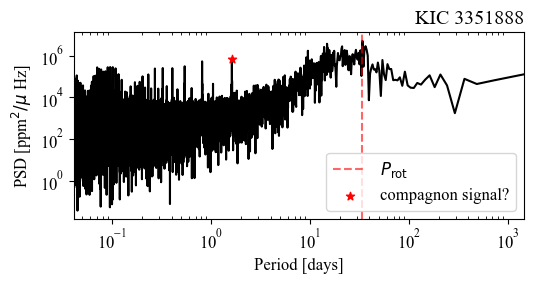

In [18]:
fig4, ax4 = plot_PSD(kic4, freq4, psd4, Prot4)
ax4.axvline(Prot4, color='red', linestyle='--', alpha=0.6, label=r'$P_{\rm rot}$')
ax4.scatter(convert_freq_to_Porb(freq_max4),psd_max4 , color = 'red', marker = "*", label='compagnon signal?', zorder=100) 
plt.legend()
fig4.savefig(f'figures/{kic4}_psd_compagnon.png', dpi=300)
plt.show()

KIC 3351888: P = 1.63 days


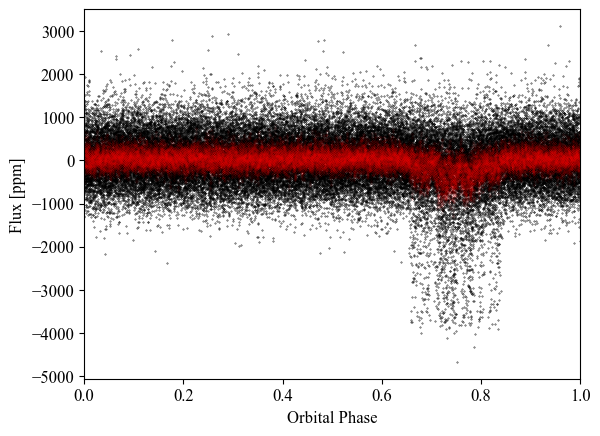

In [19]:
freq_max4, psd_max4 = find_compagnon_peak(freq4, psd4, Prot4)
Porb4 = convert_freq_to_Porb(freq_max4)
print(f'KIC {kic4}: P = {Porb4:.2f} days')
fig5, ax5 = plot_phase_fold(t4, v4, Porb4) #takes a few seconds...
fig5.savefig(f'figures/{kic4}_phase_folding.png', dpi=300)

Folded at the detected period, the light curve shows no visible modulation: the points scatter evenly around zero at every phase. The peak found in the PSD does not translate into a coherent signal.

## Summary

- A high peak in the PSD is not a companion by itself: **compare it with $P_{\rm rot}$ and its harmonics first** (KIC 9837312).
- Once stellar activity is excluded, the highest remaining peak is a **candidate** orbital period (KIC 7847566: 0.38 day).
- **Phase folding** tests the candidate:
  - stable and coherent modulation: KIC 7847566,
  - unstable signal, false positive: KIC 11154093,
  - no visible modulation: KIC 3351888.